Investigacion computacional


Raíz de referencia V*: 2.99832209 V
Energía de referencia E*: 1.05849767 uJ

Subintervalos (n) | Paso h (us) | E_Trapecio (uJ) | Err_Trap (%) | E_Simpson (uJ) | Err_Simp (%)
--------------------------------------------------------------------------------------------
                4 |      0.3000 |        1.056742 |     0.16583% |       1.058175 |    0.030492%
                6 |      0.2000 |        1.057699 |     0.07548% |       1.058438 |    0.005648%
               12 |      0.1000 |        1.058295 |     0.01914% |       1.058494 |    0.000356%
               24 |      0.0500 |        1.058447 |     0.00480% |       1.058497 |    0.000022%
               60 |      0.0200 |        1.058490 |     0.00077% |       1.058498 |    0.000001%


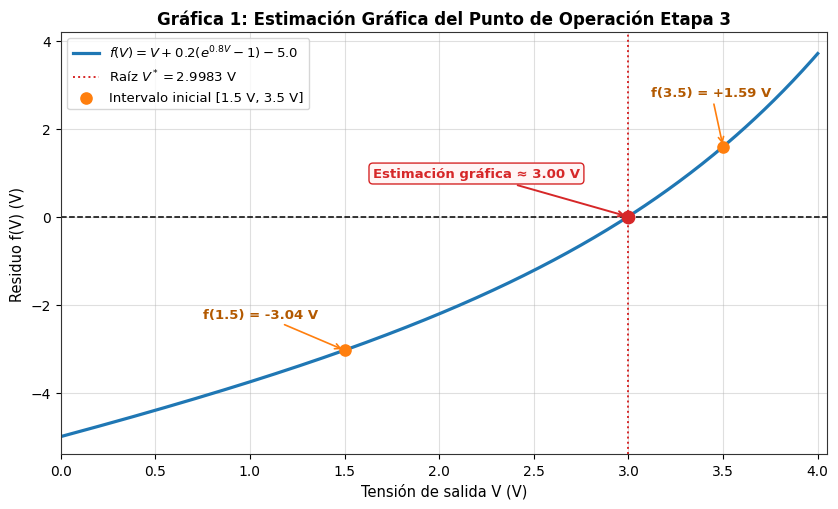

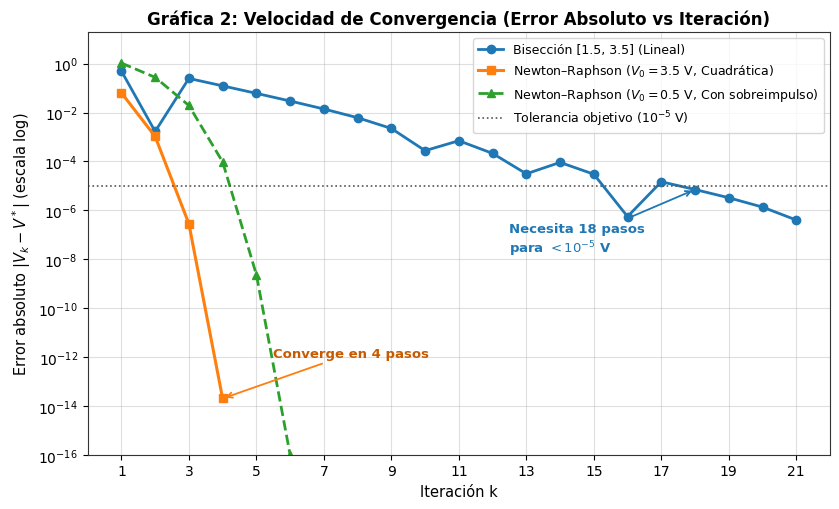

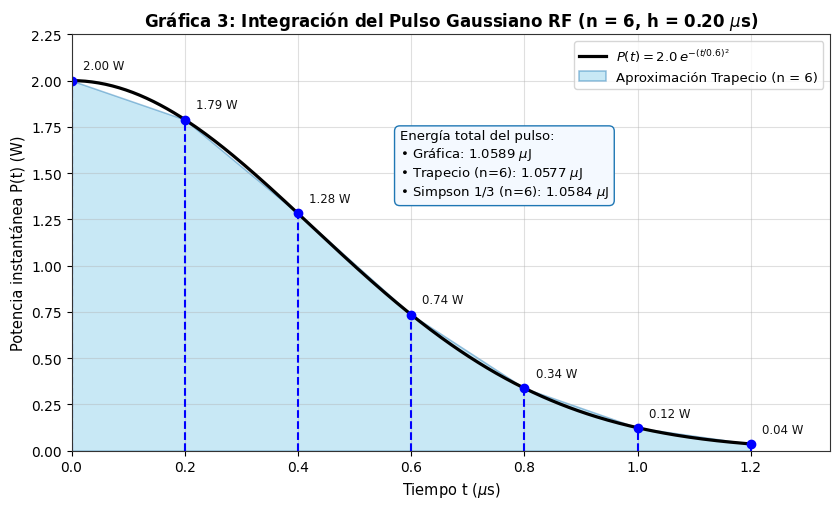

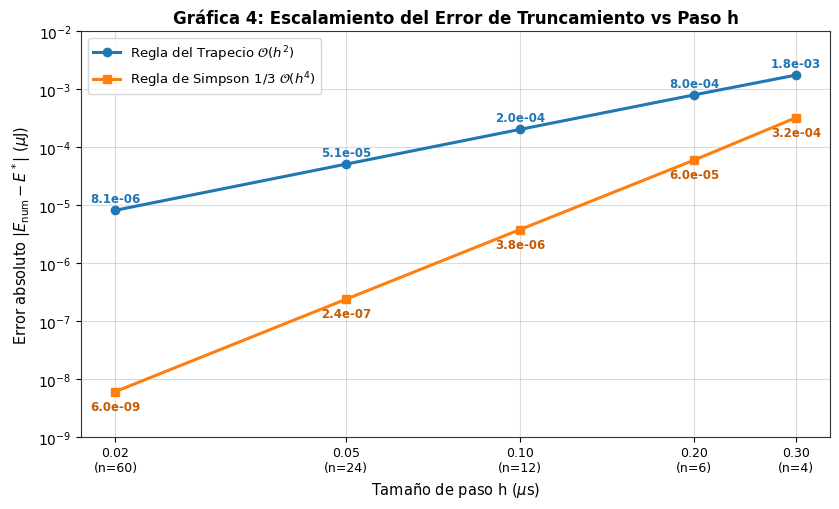

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, optimize

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

# ==============================================================================
# 1. DEFINICIÓN DE FUNCIONES DEL SISTEMA RF
# ==============================================================================
def f_amp(V):
    return V + 0.2 * (np.exp(0.8 * V) - 1.0) - 5.0

def df_amp(V):
    return 1.0 + 0.16 * np.exp(0.8 * V)

def P_pulso(t):
    return 2.0 * np.exp(-(t / 0.6)**2)

V_exact = optimize.brentq(f_amp, 0.0, 5.0, xtol=1e-14)
E_exact, _ = integrate.quad(P_pulso, 0.0, 1.2, epsabs=1e-14)

print(f"Raíz de referencia V*: {V_exact:.8f} V")
print(f"Energía de referencia E*: {E_exact:.8f} uJ\n")

# ==============================================================================
# 2. MÉTODOS ITERATIVOS DE RAÍCES
# ==============================================================================
def biseccion(func, a, b, tol=1e-6, max_iter=50):
    historial = []
    for k in range(1, max_iter + 1):
        c = 0.5 * (a + b)
        fc = func(c)
        historial.append((k, c, abs(c - V_exact)))
        if 0.5 * (b - a) < tol or abs(fc) < tol:
            break
        if func(a) * fc < 0:
            b = c
        else:
            a = c
    return historial

def newton_raphson(func, dfunc, v0, tol=1e-6, max_iter=50):
    historial = []
    v = v0
    for k in range(1, max_iter + 1):
        v_next = v - func(v) / dfunc(v)
        historial.append((k, v_next, abs(v_next - V_exact)))
        if abs(v_next - v) < tol:
            break
        v = v_next
    return historial

hist_bis = biseccion(f_amp, 1.5, 3.5, tol=1e-6)
hist_nr_35 = newton_raphson(f_amp, df_amp, v0=3.5, tol=1e-6)
hist_nr_05 = newton_raphson(f_amp, df_amp, v0=0.5, tol=1e-6)

# ==============================================================================
# 3. INTEGRACIÓN NUMÉRICA (TRAPECIO VS SIMPSON 1/3)
# ==============================================================================
subintervalos = [4, 6, 12, 24, 60]
err_trap_list, err_simp_list, h_list = [], [], []

print("Subintervalos (n) | Paso h (us) | E_Trapecio (uJ) | Err_Trap (%) | E_Simpson (uJ) | Err_Simp (%)")
print("-" * 92)
for n in subintervalos:
    t_nodes = np.linspace(0.0, 1.2, n + 1)
    y_nodes = P_pulso(t_nodes)
    h = 1.2 / n
    e_t = integrate.trapezoid(y_nodes, t_nodes)
    e_s = integrate.simpson(y_nodes, x=t_nodes)
    h_list.append(h)
    err_trap_list.append(abs(e_t - E_exact))
    err_simp_list.append(abs(e_s - E_exact))
    print(f"{n:17d} | {h:11.4f} | {e_t:15.6f} | {abs(e_t-E_exact)/E_exact*100:11.5f}% | {e_s:14.6f} | {abs(e_s-E_exact)/E_exact*100:11.6f}%")

# ==============================================================================
# 4. GENERACIÓN DE LAS 4 GRÁFICAS INDIVIDUALES (IDÉNTICAS AL INFORME)
# ==============================================================================
# Gráfica 1
fig1, ax1 = plt.subplots(figsize=(8.5, 5.2))
V_grid = np.linspace(0, 4.0, 400)
ax1.plot(V_grid, f_amp(V_grid), color='#1f77b4', lw=2.3, label=r'$f(V) = V + 0.2(e^{0.8V}-1) - 5.0$')
ax1.axhline(0, color='k', lw=1.1, ls='--')
ax1.axvline(V_exact, color='#d62728', ls=':', lw=1.4, label=f'Raíz $V^* = {V_exact:.4f}$ V')
ax1.scatter([1.5, 3.5], [f_amp(1.5), f_amp(3.5)], color='#ff7f0e', s=65, zorder=5, label='Intervalo inicial [1.5 V, 3.5 V]')
ax1.scatter([V_exact], [0], color='#d62728', s=80, zorder=6)
ax1.annotate(f'f(1.5) = {f_amp(1.5):.2f} V', xy=(1.5, f_amp(1.5)), xytext=(0.75, -2.3),
             arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.2), fontsize=9.5, fontweight='bold', color='#b35900')
ax1.annotate(f'f(3.5) = +{f_amp(3.5):.2f} V', xy=(3.5, f_amp(3.5)), xytext=(3.12, 2.75),
             arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.2), fontsize=9.5, fontweight='bold', color='#b35900')
ax1.annotate('Estimación gráfica ≈ 3.00 V', xy=(V_exact, 0), xytext=(1.65, 0.9),
             arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.4), fontsize=9.5, fontweight='bold', color='#d62728',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#fff5f5', edgecolor='#d62728'))
ax1.set_title('Gráfica 1: Estimación Gráfica del Punto de Operación Etapa 3', fontsize=12, fontweight='bold')
ax1.set_xlabel('Tensión de salida V (V)', fontsize=10.5)
ax1.set_ylabel('Residuo f(V) (V)', fontsize=10.5)
ax1.set_xlim(0, 4.05)
ax1.set_ylim(-5.4, 4.2)
ax1.grid(True, alpha=0.4)
ax1.legend(loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.savefig('grafica_1_raiz.png', dpi=300)
plt.show()

# Gráfica 2
fig2, ax2 = plt.subplots(figsize=(8.5, 5.2))
ax2.semilogy([x[0] for x in hist_bis], [max(x[2], 1e-16) for x in hist_bis], 'o-', color='#1f77b4', lw=2,
             label='Bisección [1.5, 3.5] (Lineal)')
ax2.semilogy([x[0] for x in hist_nr_35], [max(x[2], 1e-16) for x in hist_nr_35], 's-', color='#ff7f0e', lw=2.2,
             label=r'Newton–Raphson ($V_0 = 3.5\ \mathrm{V}$, Cuadrática)')
ax2.semilogy([x[0] for x in hist_nr_05], [max(x[2], 1e-16) for x in hist_nr_05], '^--', color='#2ca02c', lw=2,
             label=r'Newton–Raphson ($V_0 = 0.5\ \mathrm{V}$, Con sobreimpulso)')
ax2.axhline(1e-5, color='#555555', ls=':', lw=1.2, label='Tolerancia objetivo ($10^{-5}$ V)')
ax2.annotate('Converge en 4 pasos', xy=(4, hist_nr_35[3][2]), xytext=(5.5, 1e-12),
             arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.3), fontsize=9.5, fontweight='bold', color='#c85a00')
ax2.annotate('Necesita 18 pasos\npara $< 10^{-5}$ V', xy=(18, hist_bis[17][2]), xytext=(12.5, 2e-8),
             arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.3), fontsize=9.5, fontweight='bold', color='#1f77b4')
ax2.set_title('Gráfica 2: Velocidad de Convergencia (Error Absoluto vs Iteración)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Iteración k', fontsize=10.5)
ax2.set_ylabel(r'Error absoluto $|V_k - V^*|$ (escala log)', fontsize=10.5)
ax2.set_xticks(range(1, 22, 2))
ax2.set_ylim(1e-16, 20)
ax2.grid(True, which='both', alpha=0.4)
ax2.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('grafica_2_convergencia.png', dpi=300)
plt.show()

# Gráfica 3
fig3, ax3 = plt.subplots(figsize=(8.5, 5.2))
t_fine = np.linspace(0, 1.2, 300)
t_6 = np.linspace(0, 1.2, 7)
p_6 = P_pulso(t_6)
ax3.plot(t_fine, P_pulso(t_fine), 'k-', lw=2.3, label=r'$P(t) = 2.0\,e^{-(t/0.6)^2}$')
ax3.fill_between(t_6, p_6, color='skyblue', alpha=0.45, edgecolor='#1f77b4', lw=1.1, label='Aproximación Trapecio (n = 6)')
ax3.stem(t_6, p_6, linefmt='b--', markerfmt='bo', basefmt=' ')
for ti, pi in zip(t_6, p_6):
    ax3.annotate(f'{pi:.2f} W', xy=(ti, pi), xytext=(ti + 0.02, pi + 0.06), fontsize=8.5, color='#111111')
ax3.text(0.58, 1.38,
         'Energía total del pulso:\n'
         '• Gráfica: 1.0589 $\\mu$J\n'
         '• Trapecio (n=6): 1.0577 $\\mu$J\n'
         '• Simpson 1/3 (n=6): 1.0584 $\\mu$J',
         fontsize=9.5, bbox=dict(boxstyle='round,pad=0.4', facecolor='#f4f9ff', edgecolor='#1f77b4'))
ax3.set_title(r'Gráfica 3: Integración del Pulso Gaussiano RF (n = 6, h = 0.20 $\mu$s)', fontsize=12, fontweight='bold')
ax3.set_xlabel(r'Tiempo t ($\mu$s)', fontsize=10.5)
ax3.set_ylabel('Potencia instantánea P(t) (W)', fontsize=10.5)
ax3.set_xlim(0, 1.34)
ax3.set_ylim(0, 2.25)
ax3.grid(True, alpha=0.4)
ax3.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.savefig('grafica_3_pulso.png', dpi=300)
plt.show()

# Gráfica 4
fig4, ax4 = plt.subplots(figsize=(8.5, 5.2))
ax4.loglog(h_list, err_trap_list, 'o-', color='#1f77b4', lw=2.2, markersize=6, label=r'Regla del Trapecio $\mathcal{O}(h^2)$')
ax4.loglog(h_list, err_simp_list, 's-', color='#ff7f0e', lw=2.2, markersize=6, label=r'Regla de Simpson 1/3 $\mathcal{O}(h^4)$')
for hi, et, es in zip(h_list, err_trap_list, err_simp_list):
    ax4.annotate(f'{et:.1e}', xy=(hi, et), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8.5, color='#1f77b4', fontweight='bold')
    ax4.annotate(f'{es:.1e}', xy=(hi, es), xytext=(0, -13), textcoords='offset points', ha='center', fontsize=8.5, color='#c85a00', fontweight='bold')
ax4.set_title('Gráfica 4: Escalamiento del Error de Truncamiento vs Paso h', fontsize=12, fontweight='bold')
ax4.set_xlabel(r'Tamaño de paso h ($\mu$s)', fontsize=10.5)
ax4.set_ylabel(r'Error absoluto $|E_{\mathrm{num}} - E^*|$ ($\mu$J)', fontsize=10.5)
ax4.set_xticks(h_list)
ax4.set_xticklabels([f'{h:.2f}\n(n={n})' for h, n in zip(h_list, subintervalos)], fontsize=9)
ax4.minorticks_off()
ax4.set_ylim(1e-9, 1e-2)
ax4.grid(True, which='major', alpha=0.45)
ax4.legend(loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.savefig('grafica_4_error_integracion.png', dpi=300)
plt.show()